<a href="https://colab.research.google.com/github/Fyyskie/TUBES_KB_2026_KelasB_Kelompok04/blob/main/W12_EDA_BASELINE_NN_KEL4/TUBES_KECEBUT_KEL4_W12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROGRESS WEEK 12**

# **Memvalidasi kualitas dataset, melakukan Exploratory Data Analysis (EDA), menganalisis missing-values, dan melakukan pembagian data (train/validation/test) secara aman tanpa ada kebocoran masa depan.**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Membaca kelima dataset
df_2011 = pd.read_csv('gt_2011.csv')
df_2012 = pd.read_csv('gt_2012.csv')
df_2013 = pd.read_csv('gt_2013.csv')
df_2014 = pd.read_csv('gt_2014.csv')
df_2015 = pd.read_csv('gt_2015.csv')

# 2. Menggabungkan data secara berurutan (Chronological)
df_all = pd.concat([df_2011, df_2012, df_2013, df_2014, df_2015], ignore_index=True)

print(f"Total baris data: {df_all.shape[0]}, Total kolom: {df_all.shape[1]}")
display(df_all.head())

Total baris data: 36733, Total kolom: 11


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


### **Penjelasan Proses Pemuatan Data**
Pada sel di atas, kelima file dataset dari tahun 2011 hingga 2015 dibaca dan diubah menjadi format DataFrame Pandas. Setelah itu, penggabungan data dilakukan secara kronologis menggunakan fungsi `concat`. Parameter `ignore_index=True` diterapkan agar indeks pada data gabungan diurutkan ulang dari nol, sehingga tumpang tindih indeks dapat dihindari. Terakhir, dimensi total data dan lima baris pertama ditampilkan agar struktur data dapat diverifikasi sejak awal.

### **Exploratory Data Analysis (EDA) & Missing Values Analysis**
Langkah ini penting untuk memahami distribusi data, mendeteksi nilai kosong, dan melihat korelasi antar fitur sensor dengan target (CO dan NOX).

--- Analisis Missing Values ---


,0
AT,0
AP,0
AH,0
AFDP,0
GTEP,0
TIT,0
TAT,0
TEY,0
CDP,0
CO,0



Kesimpulan: Dataset bersih, tidak ada missing values.

--- Statistik Deskriptif ---


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
count,36733.000000,36733.000000,36733.000000,36733.000000,36733.000000,36733.000000,36733.000000,36733.000000,36733.000000,36733.000000,36733.000000
mean,17.712726,1013.070165,77.867015,3.925518,25.563801,1081.428084,546.158517,133.506404,12.060525,2.372468,65.293067
std,7.447451,6.463346,14.461355,0.773936,4.195957,17.536373,6.842360,15.618634,1.088795,2.262672,11.678357
min,-6.234800,985.850000,24.085000,2.087400,17.698000,1000.800000,511.040000,100.020000,9.851800,0.000388,25.905000
25%,11.781000,1008.800000,68.188000,3.355600,23.129000,1071.800000,544.720000,124.450000,11.435000,1.182400,57.162000
50%,17.801000,1012.600000,80.470000,3.937700,25.104000,1085.900000,549.880000,133.730000,11.965000,1.713500,63.849000
75%,23.665000,1017.000000,89.376000,4.376900,29.061000,1097.000000,550.040000,144.080000,12.855000,2.842900,71.548000
max,37.103000,1036.600000,100.200000,7.610600,40.716000,1100.900000,550.610000,179.500000,15.159000,44.103000,119.910000


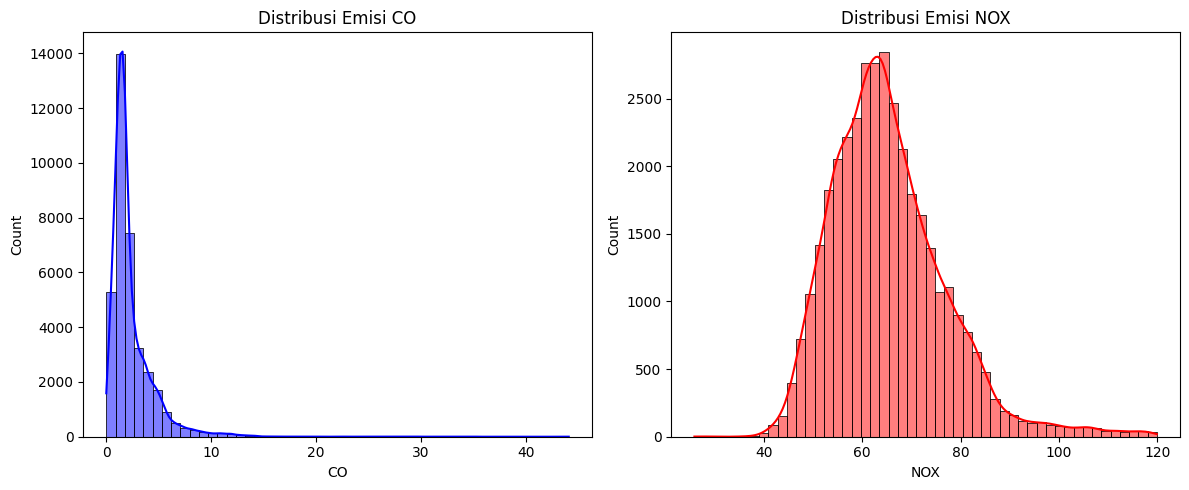

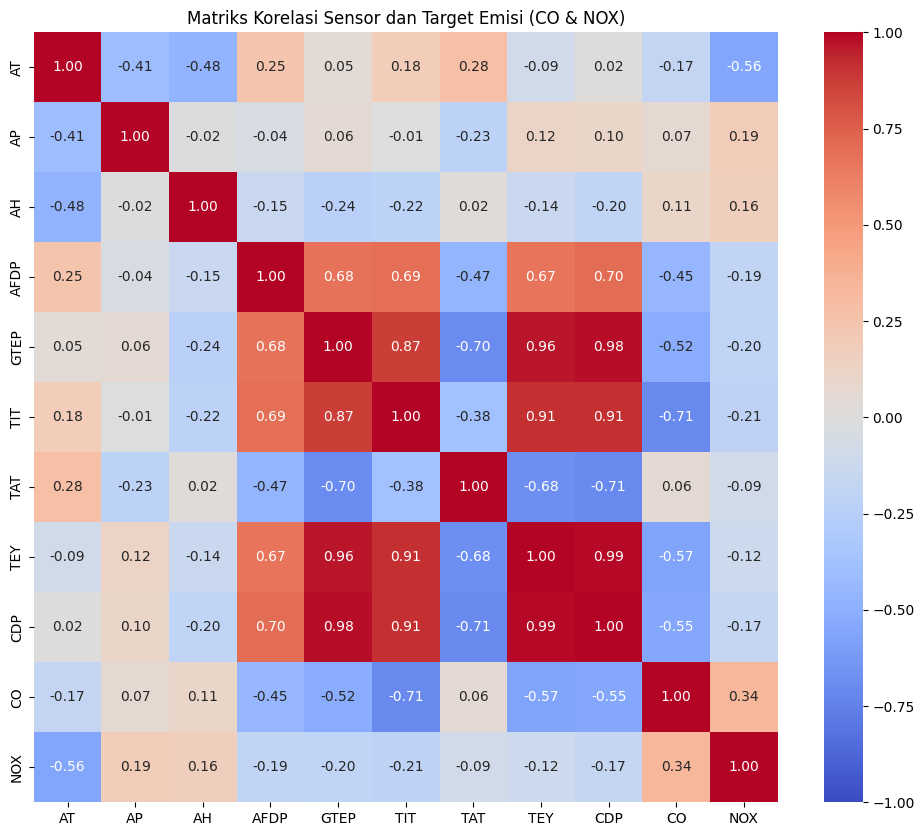

In [ ]:
# 1. Analisis Missing Values
print("--- Analisis Missing Values ---")
missing_values = df_all.isnull().sum()
display(missing_values)

if missing_values.sum() == 0:
    print("\nKesimpulan: Dataset bersih, tidak ada missing values.\n")
else:
    print("\nKesimpulan: Terdapat missing values, perlu dilakukan imputasi atau drop data.\n")

# 2. Statistik Deskriptif Dataset
print("--- Statistik Deskriptif ---")
display(df_all.describe())

# 3. Visualisasi Distribusi Target (CO & NOX)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df_all['CO'], bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribusi Emisi CO')

sns.histplot(df_all['NOX'], bins=50, kde=True, ax=axes[1], color='red')
axes[1].set_title('Distribusi Emisi NOX')
plt.tight_layout()
plt.show()

# 4. Correlation Matrix Heatmap
plt.figure(figsize=(12, 10))
# Menggunakan method pearson correlation
correlation_matrix = df_all.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriks Korelasi Sensor dan Target Emisi (CO & NOX)')
plt.show()


### **Penjelasan Exploratory Data Analysis (EDA)**
Pada tahapan ini, analisis terhadap nilai yang hilang (*missing values*) dilakukan untuk memvalidasi kebersihan dataset. Selanjutnya, statistik deskriptif dari dataset ditampilkan agar karakteristik distribusi nilai dasar dapat dipahami. Distribusi untuk masing-masing target emisi (CO dan NOX) divisualisasikan menggunakan plot histogram. Sebagai langkah akhir dari EDA, peta korelasi (*heatmap*) dibuat agar hubungan linier antar fitur sensor dan variabel target dapat diidentifikasi, yang mana sangat penting untuk analisis pemilihan fitur pada tahap berikutnya.

# **Memproses data dan melatih model Neural Network sebelum dievaluasi.**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 1. Pisahkan fitur (X) dan target (CO dan NOX)
X = df_all.drop(columns=['CO', 'NOX'])
y = df_all[['CO', 'NOX']]

# 2. Bagi data menjadi train (80%) dan test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scaling fitur dan target
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

# 4. Bangun arsitektur Baseline Neural Network
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(2) # 2 output untuk prediksi CO dan NOX sekaligus
])

model.compile(optimizer='adam', loss='mse')

# 5. Latih model
history = model.fit(
    X_train_scaled, y_train_scaled,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3552 - val_loss: 0.2978
Epoch 2/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2806 - val_loss: 0.2825
Epoch 3/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2675 - val_loss: 0.2706
Epoch 4/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.2586 - val_loss: 0.2741
Epoch 5/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2531 - val_loss: 0.2627
Epoch 6/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2470 - val_loss: 0.2551
Epoch 7/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2415 - val_loss: 0.2574
Epoch 8/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2397 - val_loss: 0.2492
Epoch 9/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2345 - val_loss: 0.2411
Epoch 10/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2292 - val_loss: 0.2330
Epoch 11/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2274 - val_loss: 0.2326
Epoch 12/50
735/735 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step

### **Penjelasan Preprocessing dan Pembuatan Model Baseline**
Pada sel ini, pemisahan antara variabel fitur (X) dan target (CO dan NOX) dilakukan. Kemudian, dataset dibagi menjadi data latih (80%) dan data uji (20%) secara acak namun terkontrol (`random_state=42`) agar kebocoran data (*data leakage*) dapat dicegah dengan aman. Standarisasi (*StandardScaler*) diaplikasikan pada fitur maupun target agar proses konvergensi model Neural Network menjadi lebih optimal dan stabil. Selanjutnya, arsitektur *Baseline Neural Network* dibangun menggunakan model sekuensial yang terdiri dari dua *hidden layer* dan satu *output layer* dengan dua neuron. Model ini kemudian dikompilasi menggunakan fungsi kerugian *Mean Squared Error* (MSE) dan dilatih selama 50 *epoch* di mana 20% dari data latih disisihkan sebagai set validasi.

# **EVALUASI RUBRIK**

230/230 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
--- Evaluasi Target CO ---
MAE: 0.5657 | RMSE: 1.1490 | R²: 0.7572
--- Evaluasi Target NOx ---
MAE: 3.0248 | RMSE: 4.4195 | R²: 0.8526


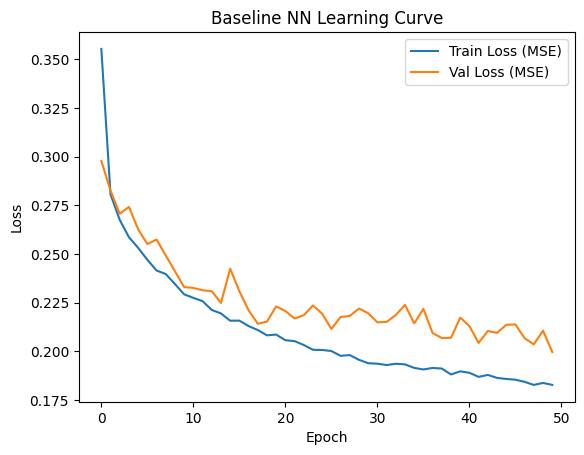

In [ ]:
# Prediksi data test
y_pred_scaled = model.predict(X_test_scaled)

# Kembalikan ke skala aslinya (Inverse Transform)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_asli = y_test.values

# Hitung Metrik untuk CO (Kolom 0)
mae_co = mean_absolute_error(y_test_asli[:, 0], y_pred[:, 0])
rmse_co = np.sqrt(mean_squared_error(y_test_asli[:, 0], y_pred[:, 0]))
r2_co = r2_score(y_test_asli[:, 0], y_pred[:, 0])

# Hitung Metrik untuk NOx (Kolom 1)
mae_nox = mean_absolute_error(y_test_asli[:, 1], y_pred[:, 1])
rmse_nox = np.sqrt(mean_squared_error(y_test_asli[:, 1], y_pred[:, 1]))
r2_nox = r2_score(y_test_asli[:, 1], y_pred[:, 1])

print(f"--- Evaluasi Target CO ---")
print(f"MAE: {mae_co:.4f} | RMSE: {rmse_co:.4f} | R²: {r2_co:.4f}")
print(f"--- Evaluasi Target NOx ---")
print(f"MAE: {mae_nox:.4f} | RMSE: {rmse_nox:.4f} | R²: {r2_nox:.4f}")

# Plot Kurva Loss (Validation vs Training)
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Val Loss (MSE)')
plt.title('Baseline NN Learning Curve')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

### **Penjelasan Evaluasi Model**
Pada blok terakhir ini, prediksi terhadap data uji dilakukan oleh model yang telah dilatih. Hasil prediksi yang sebelumnya diskalakan kemudian dikembalikan ke skala aslinya (*inverse transform*) agar nilai *error* yang dihasilkan dapat diinterpretasikan secara fisik dan logis. Metrik evaluasi seperti MAE, RMSE, dan R² dihitung dan ditampilkan secara terpisah untuk masing-masing target (CO dan NOX). Sebagai penutup, kurva *loss* (*Training* vs *Validation*) divisualisasikan agar indikasi *overfitting* atau *underfitting* pada model dapat dianalisis secara visual.

In [ ]:
# Menyimpan data gabungan menjadi satu file CSV baru
df_all.to_csv('data_turbin.csv', index=False)

In [ ]:
import joblib

# Menyimpan fungsi normalisasi (Scaler)
joblib.dump(scaler_X, 'scaler_X.pkl')
joblib.dump(scaler_y, 'scaler_y.pkl')

# Menyimpan arsitektur dan bobot model Neural Network
model.save('baseline_model.h5')